# ⚽ Joueurs et effectif — Ligue des champions

## Objectif

Étudier si la valeur pré-match, l’âge des joueurs, la rotation et la dépendance au meilleur buteur sont associés aux résultats des matchs de C1. Le livrable final est `output/joueurs_par_match.csv`, une ligne par équipe et par match.

Le notebook suit le fil **Question → Résultat → Interprétation → Limite**. Les variables de rotation et de dépendance au buteur proviennent de la **saison précédente**, jamais de la fin de la saison en cours : aucun but inscrit après le match étudié ne peut donc entrer dans ces variables.

## Données nécessaires

Les fichiers de base (`games.csv`, `appearances.csv`, `game_events.csv`, `players.csv`) et `player_valuations.csv` doivent être placés dans `data/`. Ils proviennent du jeu Kaggle [Player Scores de Transfermarkt](https://www.kaggle.com/datasets/davidcariboo/player-scores). `player_valuations.csv` est indispensable au calcul de la valeur pré-match ; il n’est pas commité avec le code. Si tu ne l’as pas, télécharge-le depuis Kaggle et ajoute-le localement à `data/`.

**Aucune dépendance à `competitions.csv`** : le notebook utilise la colonne `competition_type` de `games.csv`. Les CSV de résultats ne sont pas committés ; chaque personne les génère localement en exécutant le notebook.

## 1. Question — Les scores reflètent-ils les buts du match, sans les tirs au but ?

Les tirs d’une séance de tirs au but ne font pas partie du score du match. On recalcule les buts à partir des événements `Goals` et on vérifie que les écarts avec le score enregistré concernent bien des matchs avec séance de tirs au but.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

# Résolution du chemin depuis la racine du dépôt ou depuis analyse/.
DOSSIER_PROJET = next(
    (chemin for chemin in [Path.cwd(), *Path.cwd().parents] if (chemin / "data").is_dir()),
    None,
)
if DOSSIER_PROJET is None:
    raise FileNotFoundError("Dossier data/ introuvable. Ouvre le notebook depuis le dépôt du projet.")
DOSSIER_DATA = DOSSIER_PROJET / "data"
DOSSIER_SORTIE = DOSSIER_PROJET / "output"
FICHIERS_REQUIS = [
    "games.csv", "appearances.csv", "game_events.csv", "players.csv", "player_valuations.csv"
]
FICHIERS_MANQUANTS = [nom for nom in FICHIERS_REQUIS if not (DOSSIER_DATA / nom).is_file()]
if FICHIERS_MANQUANTS:
    raise FileNotFoundError(
        "Fichier(s) absent(s) de data/: " + ", ".join(FICHIERS_MANQUANTS)
        + ". Les fichiers du jeu Player Scores, y compris player_valuations.csv, "
        + "doivent être téléchargés sur Kaggle et placés dans data/."
    )

matchs = pd.read_csv(
    DOSSIER_DATA / "games.csv",
    usecols=[
        "game_id", "competition_id", "competition_type", "season", "date",
        "home_club_id", "away_club_id", "home_club_name", "away_club_name",
        "home_club_goals", "away_club_goals",
    ],
    parse_dates=["date"],
)
apparitions_source = pd.read_csv(
    DOSSIER_DATA / "appearances.csv",
    usecols=["game_id", "player_id", "player_club_id", "minutes_played", "goals"],
)
evenements = pd.read_csv(
    DOSSIER_DATA / "game_events.csv",
    usecols=["game_id", "type", "club_id"],
)
players = pd.read_csv(
    DOSSIER_DATA / "players.csv",
    usecols=["player_id", "date_of_birth"],
    parse_dates=["date_of_birth"],
)

matchs_c1 = matchs.loc[
    matchs["competition_id"].eq("CL")
    & matchs["home_club_goals"].notna()
    & matchs["away_club_goals"].notna()
].copy()
evenements_c1 = evenements.loc[evenements["game_id"].isin(matchs_c1["game_id"])]
matchs_avec_tirs_au_but = set(
    evenements_c1.loc[evenements_c1["type"].eq("Shootout"), "game_id"]
)
buts_evenements = (
    evenements_c1.loc[evenements_c1["type"].eq("Goals")]
    .groupby(["game_id", "club_id"])
    .size()
    .rename("buts_evenements")
    .reset_index()
)
matchs_c1 = matchs_c1.merge(
    buts_evenements.rename(columns={"club_id": "home_club_id", "buts_evenements": "buts_domicile_corriges"}),
    on=["game_id", "home_club_id"],
    how="left",
    validate="one_to_one",
).merge(
    buts_evenements.rename(columns={"club_id": "away_club_id", "buts_evenements": "buts_exterieur_corriges"}),
    on=["game_id", "away_club_id"],
    how="left",
    validate="one_to_one",
)
matchs_c1[["buts_domicile_corriges", "buts_exterieur_corriges"]] = (
    matchs_c1[["buts_domicile_corriges", "buts_exterieur_corriges"]].fillna(0).astype(int)
)
matchs_c1["score_enregistre_domicile"] = matchs_c1["home_club_goals"].astype(int)
matchs_c1["score_enregistre_exterieur"] = matchs_c1["away_club_goals"].astype(int)
erreur_score = (
    matchs_c1["score_enregistre_domicile"].ne(matchs_c1["buts_domicile_corriges"])
    | matchs_c1["score_enregistre_exterieur"].ne(matchs_c1["buts_exterieur_corriges"])
)
matchs_avec_ecart = set(matchs_c1.loc[erreur_score, "game_id"])
if not matchs_avec_ecart.issubset(matchs_avec_tirs_au_but):
    raise ValueError(
        "Des scores ne correspondent pas aux événements sans séance de tirs au but. "
        "Vérifie les versions de games.csv et game_events.csv avant de continuer."
    )
matchs_c1["home_club_goals"] = matchs_c1["buts_domicile_corriges"]
matchs_c1["away_club_goals"] = matchs_c1["buts_exterieur_corriges"]

comparaison_scores = matchs_c1.loc[
    erreur_score,
    ["date", "home_club_name", "away_club_name", "score_enregistre_domicile", "score_enregistre_exterieur", "buts_domicile_corriges", "buts_exterieur_corriges"],
].copy()
comparaison_scores["tirs_au_but"] = comparaison_scores.index.map(
    matchs_c1["game_id"].isin(matchs_avec_tirs_au_but).to_dict()
)
print(f"Matchs de C1 avec score vérifiable : {len(matchs_c1):,}")
print(f"Matchs avec une séance de tirs au but : {len(matchs_avec_tirs_au_but):,}")
print(f"Scores corrigés en retirant les tirs au but : {len(matchs_avec_ecart):,}")
display(comparaison_scores.reset_index(drop=True))

# Les apparitions héritent du type, de la compétition, de la saison et de la date
# officiels de games.csv : competitions.csv n'est pas nécessaire.
infos_match = matchs[["game_id", "competition_id", "competition_type", "season", "date"]]
apparitions = apparitions_source.merge(
    infos_match,
    on="game_id",
    how="inner",
    validate="many_to_one",
)
apparitions = apparitions.loc[apparitions["minutes_played"].gt(0)].copy()
print(f"Apparitions avec minutes jouées : {len(apparitions):,}")

Matchs de C1 avec score vérifiable : 1,871
Matchs avec une séance de tirs au but : 8
Scores corrigés en retirant les tirs au but : 8


,date,home_club_name,away_club_name,score_enregistre_domicile,score_enregistre_exterieur,buts_domicile_corriges,buts_exterieur_corriges,tirs_au_but
0,2015-03-17,Atlético de Madrid,Bayer 04 Leverkusen,4,2,1,0,True
1,2016-03-15,Atlético de Madrid,PSV Eindhoven,8,7,0,0,True
2,2016-05-28,Real Madrid,Atlético de Madrid,6,4,1,1,True
3,2024-03-12,Arsenal FC,FC Porto,4,2,1,0,True
4,2024-03-13,Atlético de Madrid,Inter Milan,5,3,2,1,True
5,2024-04-17,Manchester City,Real Madrid,4,5,1,1,True
6,2025-03-11,Liverpool FC,Paris Saint-Germain,1,5,0,1,True
7,2025-03-12,Atlético de Madrid,Real Madrid,3,4,1,0,True


Apparitions avec minutes jouées : 1,894,347


## 2. Question — Quels indicateurs pouvait-on connaître avant chaque match ?

- **Valeur de l’effectif :** dernière valeur marchande de chaque joueur strictement antérieure à la date du match.
- **Âge moyen :** âge le jour du match, calculé depuis `players.csv`.
- **Rotation et dépendance au buteur :** chiffres de la saison précédente dans le championnat national et en C1. La saison précédente évite de faire entrer dans un match de septembre des apparitions et buts de mai de la saison en cours.

On ne considère comme joueur utilisé qu’un joueur ayant joué au moins une minute. Les clubs-saisons incomplets restent visibles grâce à un indicateur de couverture.

In [2]:
# Type de compétition dérivé directement de games.csv.
apparitions_stats = apparitions.loc[
    apparitions["competition_id"].eq("CL")
    | apparitions["competition_type"].eq("domestic_league")
].copy()
apparitions_stats["type_indicateur"] = np.where(
    apparitions_stats["competition_id"].eq("CL"), "C1", "championnat"
)
cles_stats = ["player_club_id", "season", "type_indicateur"]

# Nombre de joueurs et buts par joueur sur chaque saison terminée.
buts_par_joueur = (
    apparitions_stats.groupby(cles_stats + ["player_id"])["goals"]
    .sum()
    .rename("buts_joueur")
    .reset_index()
)
stats_saison = (
    buts_par_joueur.groupby(cles_stats)
    .agg(
        nb_joueurs_utilises=("player_id", "nunique"),
        buts_club_saison=("buts_joueur", "sum"),
        buts_meilleur_buteur=("buts_joueur", "max"),
    )
    .reset_index()
)
stats_saison["part_buts_meilleur_buteur"] = (
    stats_saison["buts_meilleur_buteur"]
    / stats_saison["buts_club_saison"].where(stats_saison["buts_club_saison"].gt(0))
)

# Mesurer la complétude des apparitions saisonnières : nombre de matchs observés
# où au moins 11 joueurs ont joué, rapporté à tous les matchs de ce club.
matchs_stats = matchs.loc[
    matchs["competition_id"].eq("CL")
    | matchs["competition_type"].eq("domestic_league"),
    ["game_id", "season", "competition_id", "competition_type", "home_club_id", "away_club_id"],
].copy()
matchs_stats["type_indicateur"] = np.where(matchs_stats["competition_id"].eq("CL"), "C1", "championnat")
domicile_stats = matchs_stats[["game_id", "season", "type_indicateur", "home_club_id"]].rename(columns={"home_club_id": "player_club_id"})
exterieur_stats = matchs_stats[["game_id", "season", "type_indicateur", "away_club_id"]].rename(columns={"away_club_id": "player_club_id"})
matchs_club_saison = pd.concat([domicile_stats, exterieur_stats], ignore_index=True)
joueurs_par_match_saison = (
    apparitions_stats.groupby(["game_id", "player_club_id"])["player_id"]
    .nunique()
    .rename("nb_joueurs_observes_match")
    .reset_index()
)
matchs_club_saison = matchs_club_saison.merge(
    joueurs_par_match_saison,
    on=["game_id", "player_club_id"],
    how="left",
    validate="one_to_one",
)
matchs_club_saison["nb_joueurs_observes_match"] = matchs_club_saison["nb_joueurs_observes_match"].fillna(0)
couverture_saison = (
    matchs_club_saison.groupby(cles_stats)
    .agg(
        nb_matchs_saison=("game_id", "nunique"),
        part_matchs_avec_11_joueurs=("nb_joueurs_observes_match", lambda x: x.ge(11).mean()),
    )
    .reset_index()
)
stats_saison = stats_saison.merge(
    couverture_saison,
    on=cles_stats,
    how="left",
    validate="one_to_one",
)

# Décaler les statistiques d'une saison : une rencontre saison N ne voit que N-1.
colonnes_stats = [
    "player_club_id", "season", "nb_joueurs_utilises", "part_buts_meilleur_buteur",
    "buts_meilleur_buteur", "buts_club_saison", "part_matchs_avec_11_joueurs",
]
colonnes_renommees = {
    "nb_joueurs_utilises": "nb_joueurs_utilises_precedent",
    "part_buts_meilleur_buteur": "part_buts_meilleur_buteur_precedente",
    "buts_meilleur_buteur": "buts_meilleur_buteur_precedents",
    "buts_club_saison": "buts_club_precedents",
    "part_matchs_avec_11_joueurs": "couverture_saison_precedente",
}
stats_precedents = {}
for type_indicateur, suffixe in [("championnat", "championnat"), ("C1", "c1")]:
    precedent = stats_saison.loc[
        stats_saison["type_indicateur"].eq(type_indicateur), colonnes_stats
    ].copy()
    precedent["season"] += 1
    precedent = precedent.rename(columns=colonnes_renommees).rename(
        columns={
            "nb_joueurs_utilises_precedent": f"nb_joueurs_utilises_{suffixe}_precedent",
            "part_buts_meilleur_buteur_precedente": f"part_buts_meilleur_buteur_{suffixe}_precedente",
            "buts_meilleur_buteur_precedents": f"buts_meilleur_buteur_{suffixe}_precedents",
            "buts_club_precedents": f"buts_club_{suffixe}_precedents",
            "couverture_saison_precedente": f"couverture_{suffixe}_precedente",
        }
    )
    stats_precedents[suffixe] = precedent

# Le tableau de synthèse permet de vérifier que les deux catégories viennent de games.csv.
print("Apparitions analysées par catégorie :")
display(
    apparitions_stats.groupby("type_indicateur")
    .agg(nb_apparitions=("player_id", "size"), nb_saisons_club=("season", lambda x: x.nunique()))
    .reset_index()
)
print(f"Saisons-club couvertes par les matchs et apparitions : {len(stats_saison):,}")

Apparitions analysées par catégorie :


,type_indicateur,nb_apparitions,nb_saisons_club
0,C1,49536,14
1,championnat,1606099,14


Saisons-club couvertes par les matchs et apparitions : 3,785


## 3. Question — L’équipe la mieux dotée par ces indicateurs gagne-t-elle plus souvent ?

On compare chaque équipe à son adversaire, match par match. Les indicateurs de saison proviennent toujours de la saison précédente. Pour limiter les biais dus aux apparitions manquantes, l’âge et la valeur courante ne sont comparés que si les deux équipes ont au moins 11 joueurs observés et une couverture d’au moins 90 %. Les statistiques saisonnières exigent une couverture d’au moins 90 % des matchs de la saison précédente, avec au moins 11 joueurs observés dans l’effectif.

Matchs comparés : 1,871
Taux de victoire du côté à l'indicateur le plus élevé (hors nuls) :


,Indicateur,Matchs éligibles,Valeurs différentes,Valeurs égales,Victoires du côté à la valeur supérieure,Nuls,Défaites,Taux de victoire hors nuls (%)
0,Valeur pré-match de l'effectif (€),1499,1498,1,849,304,345,71.1
1,Âge moyen de l'effectif aligné (ans),1515,1515,0,651,306,558,53.8
2,Rotation en championnat — saison précédente,1363,1228,135,423,250,555,43.3
3,Rotation en C1 — saison précédente,630,567,63,254,116,197,56.3
4,Part du meilleur buteur en championnat — saiso...,1363,1353,10,592,277,484,55.0
5,Part du meilleur buteur en C1 — saison précédente,630,620,10,234,123,263,47.1


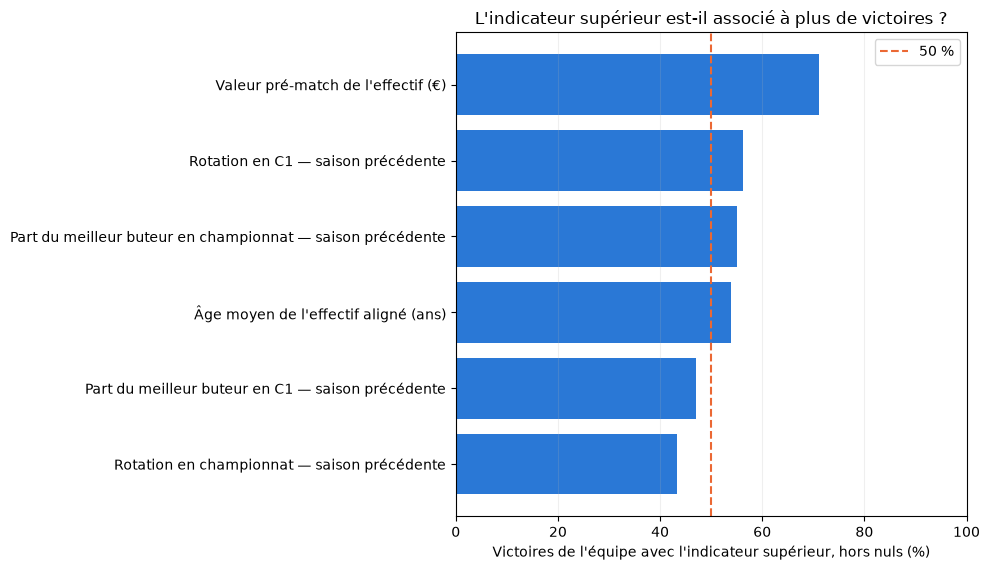

Livrable généré localement : C:\Users\Mouss\OneDrive\Desktop\CHAMPIONS-\output\joueurs_par_match.csv
Dimensions : 3,742 lignes × 26 colonnes


In [3]:
# Valeur pré-match et âge par match C1.
apparitions_c1 = apparitions.loc[apparitions["competition_id"].eq("CL")].copy()
valorisations = pd.read_csv(
    DOSSIER_DATA / "player_valuations.csv",
    usecols=["player_id", "date", "market_value_in_eur"],
    parse_dates=["date"],
).dropna(subset=["date"])
valorisations = (
    valorisations.sort_values(["player_id", "date"])
    .drop_duplicates(["player_id", "date"], keep="last")
    .sort_values("date")
)
apparitions_val = pd.merge_asof(
    apparitions_c1.sort_values("date"),
    valorisations,
    on="date",
    by="player_id",
    direction="backward",
    allow_exact_matches=False,
)
valeur_match = (
    apparitions_val.groupby(["game_id", "player_club_id"])
    .agg(
        valeur_effectif_eur_avant_match=("market_value_in_eur", lambda x: x.sum(min_count=1)),
        nb_joueurs_alignes=("player_id", "nunique"),
        nb_joueurs_avec_valeur=("market_value_in_eur", "count"),
    )
    .reset_index()
)
valeur_match["couverture_valeur"] = (
    valeur_match["nb_joueurs_avec_valeur"] / valeur_match["nb_joueurs_alignes"]
)

apparitions_age = apparitions_c1.merge(players, on="player_id", how="left", validate="many_to_one")
apparitions_age["age_au_match"] = (
    (apparitions_age["date"] - apparitions_age["date_of_birth"]).dt.days / 365.2425
)
age_match = (
    apparitions_age.groupby(["game_id", "player_club_id"])
    .agg(
        age_moyen_joueurs_alignes=("age_au_match", "mean"),
        nb_joueurs_avec_date_naissance=("age_au_match", "count"),
    )
    .reset_index()
)
age_match = age_match.merge(
    valeur_match[["game_id", "player_club_id", "nb_joueurs_alignes"]],
    on=["game_id", "player_club_id"],
    how="left",
    validate="one_to_one",
)
age_match["couverture_date_naissance"] = (
    age_match["nb_joueurs_avec_date_naissance"] / age_match["nb_joueurs_alignes"]
)

# Une ligne par équipe du match, avec score corrigé et identifiant de son club.
colonnes_match = [
    "game_id", "date", "season", "home_club_id", "away_club_id",
    "home_club_name", "away_club_name", "home_club_goals", "away_club_goals",
]
domicile = matchs_c1[colonnes_match].rename(
    columns={
        "home_club_id": "club_id", "away_club_id": "adversaire_id",
        "home_club_name": "club", "away_club_name": "adversaire",
        "home_club_goals": "buts_pour", "away_club_goals": "buts_contre",
    }
)
domicile["lieu"] = "Domicile"
exterieur = matchs_c1[colonnes_match].rename(
    columns={
        "away_club_id": "club_id", "home_club_id": "adversaire_id",
        "away_club_name": "club", "home_club_name": "adversaire",
        "away_club_goals": "buts_pour", "home_club_goals": "buts_contre",
    }
)
exterieur["lieu"] = "Extérieur"
equipes_match = pd.concat([domicile, exterieur], ignore_index=True)
equipes_match = equipes_match.merge(
    valeur_match,
    left_on=["game_id", "club_id"],
    right_on=["game_id", "player_club_id"],
    how="left",
    validate="one_to_one",
).drop(columns="player_club_id")
equipes_match = equipes_match.merge(
    age_match.drop(columns="nb_joueurs_alignes"),
    left_on=["game_id", "club_id"],
    right_on=["game_id", "player_club_id"],
    how="left",
    validate="one_to_one",
).drop(columns="player_club_id")

# Rattacher à chaque match les indicateurs de la saison précédente, séparément
# pour le championnat national et la C1.
for suffixe in ["championnat", "c1"]:
    equipes_match = equipes_match.merge(
        stats_precedents[suffixe],
        left_on=["club_id", "season"],
        right_on=["player_club_id", "season"],
        how="left",
        validate="many_to_one",
    ).drop(columns="player_club_id")
equipes_match["resultat"] = np.select(
    [
        equipes_match["buts_pour"].gt(equipes_match["buts_contre"]),
        equipes_match["buts_pour"].eq(equipes_match["buts_contre"]),
    ],
    ["Victoire", "Nul"],
    default="Défaite",
)

indicateurs = {
    "valeur_effectif_eur_avant_match": {
        "label": "Valeur pré-match de l'effectif (€)",
        "couverture": "couverture_valeur",
        "saison": False,
        "effectif_precedent": None,
    },
    "age_moyen_joueurs_alignes": {
        "label": "Âge moyen de l'effectif aligné (ans)",
        "couverture": "couverture_date_naissance",
        "saison": False,
        "effectif_precedent": None,
    },
    "nb_joueurs_utilises_championnat_precedent": {
        "label": "Rotation en championnat — saison précédente",
        "couverture": "couverture_championnat_precedente",
        "saison": True,
        "effectif_precedent": "nb_joueurs_utilises_championnat_precedent",
    },
    "nb_joueurs_utilises_c1_precedent": {
        "label": "Rotation en C1 — saison précédente",
        "couverture": "couverture_c1_precedente",
        "saison": True,
        "effectif_precedent": "nb_joueurs_utilises_c1_precedent",
    },
    "part_buts_meilleur_buteur_championnat_precedente": {
        "label": "Part du meilleur buteur en championnat — saison précédente",
        "couverture": "couverture_championnat_precedente",
        "saison": True,
        "effectif_precedent": "nb_joueurs_utilises_championnat_precedent",
    },
    "part_buts_meilleur_buteur_c1_precedente": {
        "label": "Part du meilleur buteur en C1 — saison précédente",
        "couverture": "couverture_c1_precedente",
        "saison": True,
        "effectif_precedent": "nb_joueurs_utilises_c1_precedent",
    },
}

resultats_comparaison = []
for colonne, config in indicateurs.items():
    couverture = config["couverture"]
    infos = list(dict.fromkeys([colonne, "buts_pour", "buts_contre", "nb_joueurs_alignes", couverture]))
    if config["saison"] and config["effectif_precedent"] not in infos:
        infos.append(config["effectif_precedent"])
    domicile_i = equipes_match.loc[equipes_match["lieu"].eq("Domicile")].set_index("game_id")[infos]
    exterieur_i = equipes_match.loc[equipes_match["lieu"].eq("Extérieur")].set_index("game_id")[infos]
    paires = domicile_i.join(exterieur_i, lsuffix="_domicile", rsuffix="_exterieur", how="inner")
    ecart = paires[f"{colonne}_domicile"] - paires[f"{colonne}_exterieur"]
    eligibles = ecart.notna() & paires[f"{couverture}_domicile"].ge(0.9) & paires[f"{couverture}_exterieur"].ge(0.9)
    if config["saison"]:
        effectif = config["effectif_precedent"]
        eligibles &= paires[f"{effectif}_domicile"].ge(11)
        eligibles &= paires[f"{effectif}_exterieur"].ge(11)
    else:
        eligibles &= paires["nb_joueurs_alignes_domicile"].ge(11)
        eligibles &= paires["nb_joueurs_alignes_exterieur"].ge(11)
    differentes = eligibles & ecart.ne(0)
    valeur_plus_haute_domicile = ecart.loc[differentes].gt(0)
    buts_plus_haut = np.where(
        valeur_plus_haute_domicile,
        paires.loc[differentes, "buts_pour_domicile"],
        paires.loc[differentes, "buts_pour_exterieur"],
    )
    buts_plus_bas = np.where(
        valeur_plus_haute_domicile,
        paires.loc[differentes, "buts_contre_domicile"],
        paires.loc[differentes, "buts_contre_exterieur"],
    )
    wins = int((buts_plus_haut > buts_plus_bas).sum())
    draws = int((buts_plus_haut == buts_plus_bas).sum())
    losses = int((buts_plus_haut < buts_plus_bas).sum())
    resultats_comparaison.append(
        {
            "Indicateur": config["label"],
            "Matchs éligibles": int(eligibles.sum()),
            "Valeurs différentes": int(differentes.sum()),
            "Valeurs égales": int((eligibles & ecart.eq(0)).sum()),
            "Victoires du côté à la valeur supérieure": wins,
            "Nuls": draws,
            "Défaites": losses,
            "Taux de victoire hors nuls (%)": round(100 * wins / (wins + losses), 1)
            if wins + losses else np.nan,
        }
    )
comparaison = pd.DataFrame(resultats_comparaison)
print(f"Matchs comparés : {matchs_c1['game_id'].nunique():,}")
print("Taux de victoire du côté à l'indicateur le plus élevé (hors nuls) :")
display(comparaison)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 5.8))
plot_data = comparaison.dropna(subset=["Taux de victoire hors nuls (%)"]).sort_values("Taux de victoire hors nuls (%)")
ax.barh(plot_data["Indicateur"], plot_data["Taux de victoire hors nuls (%)"], color="#2a78d6")
ax.axvline(50, color="#eb6834", linestyle="--", linewidth=1.5, label="50 %")
ax.set_xlim(0, 100)
ax.set_xlabel("Victoires de l'équipe avec l'indicateur supérieur, hors nuls (%)")
ax.set_title("L'indicateur supérieur est-il associé à plus de victoires ?")
ax.legend()
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

# Livrable local, ignoré par Git : chacun le génère en exécutant ce notebook.
colonnes_livrable = [
    "game_id", "date", "season", "club_id", "club", "adversaire_id", "adversaire",
    "lieu", "buts_pour", "buts_contre", "resultat",
    "valeur_effectif_eur_avant_match", "nb_joueurs_alignes", "nb_joueurs_avec_valeur",
    "couverture_valeur", "age_moyen_joueurs_alignes", "nb_joueurs_avec_date_naissance",
    "couverture_date_naissance", "nb_joueurs_utilises_championnat_precedent",
    "couverture_championnat_precedente", "part_buts_meilleur_buteur_championnat_precedente",
    "nb_joueurs_utilises_c1_precedent", "couverture_c1_precedente",
    "buts_meilleur_buteur_c1_precedents", "buts_club_c1_precedents",
    "part_buts_meilleur_buteur_c1_precedente",
]
DOSSIER_SORTIE.mkdir(parents=True, exist_ok=True)
livrable = equipes_match[colonnes_livrable].sort_values(["date", "game_id", "lieu"])
chemin_livrable = DOSSIER_SORTIE / "joueurs_par_match.csv"
livrable.to_csv(chemin_livrable, index=False)
print(f"Livrable généré localement : {chemin_livrable}")
print(f"Dimensions : {livrable.shape[0]:,} lignes × {livrable.shape[1]} colonnes")

## 4. Résultat et interprétation

Le tableau et le graphique ci-dessus donnent, pour chaque indicateur, la part des victoires parmi les matchs décidés lorsque les deux équipes ont des valeurs différentes. **Un taux supérieur à 50 % décrit une association** dans cet échantillon : il ne prouve pas que l’indicateur cause la victoire.

- La valeur pré-match permet de tester directement si l’effectif à plus forte valeur est aussi le plus souvent vainqueur.
- La rotation et la part du meilleur buteur utilisent uniquement la saison précédente ; elles sont disponibles avant les matchs de la saison étudiée.
- Les nuls, égalités d’indicateur et matchs exclus pour données insuffisantes sont affichés dans le tableau, afin que le pourcentage ne masque pas la taille de l’échantillon.

## 5. Limites

1. Les données historiques d’apparitions et de dates de naissance sont parfois incomplètes. Les lignes manquantes ne sont pas transformées en joueurs à valeur nulle ; la couverture est fournie et les comparaisons appliquent un seuil.
2. `player_valuations.csv` doit être obtenu séparément depuis Kaggle. Il n’est pas commité dans le dépôt ; sans lui, le notebook s’arrête avec un message expliquant le fichier à installer.
3. L’utilisation de la saison précédente évite la fuite des matchs futurs, mais une rotation ou un meilleur buteur passés ne garantissent pas la même équipe ni la même performance la saison suivante.
4. Les comparaisons ne contrôlent pas le domicile, la force de l’adversaire, les blessures, le tour de la compétition ou le format aller-retour. Ce sont des associations brutes, pas des estimations causales ni des probabilités de qualification.
5. Les scores de C1 sont recalculés depuis les événements `Goals`, à l’exclusion des événements `Shootout`. Le notebook arrête l’analyse si d’autres écarts inattendus apparaissent.

## 6. Conclusion

**L’équipe dont l’effectif vaut le plus cher gagne 71 % des matchs décisifs : c’est l’indicateur le plus fort, au niveau de l’Elo. Les autres indicateurs restent proches de 50 % et n’aident pas à prédire. La rotation en championnat semble même défavorable, mais c’est probablement un effet du niveau des clubs.**

Ces résultats sont des associations descriptives calculées sur les matchs et les valeurs de l’indicateur présentés plus haut ; ils ne démontrent pas une relation de cause à effet. La rotation et la dépendance au meilleur buteur sont calculées à partir de la saison précédente pour éviter d’utiliser des informations postérieures au match. Pour toute modélisation, les taux affichés doivent être interprétés comme des repères sur cet échantillon, et non comme des probabilités garanties pour les matchs à venir.